# Otimização de Hiperparâmetros via Algoritmo Genético
## Tech Challenge Fase 2 — Projeto 1

Este notebook implementa um **Algoritmo Genético (AG)** para otimizar os hiperparâmetros do Random Forest treinado na Fase 1.

### Por que Algoritmos Genéticos?
O espaço de hiperparâmetros do Random Forest é grande e não-contínuo — busca exaustiva (GridSearch) é cara e busca aleatória não aprende com iterações anteriores. O AG usa seleção natural para **evoluir** combinações de hiperparâmetros, convergindo para boas soluções com menos avaliações.

### Estrutura do notebook
1. Carregamento dos dados e modelo base (Fase 1)
2. Definição do espaço de busca (genes)
3. Implementação do AG com DEAP
4. Três experimentos com configurações diferentes
5. Comparativo: modelo original vs. modelo otimizado

## 1. Imports e configuração

In [1]:
import sys
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import recall_score, f1_score, accuracy_score, roc_auc_score

from deap import base, creator, tools, algorithms

sys.path.append('../src')
from evaluation import evaluate_model, plot_confusion_matrix

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)

RANDOM_STATE = 4
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print('Bibliotecas carregadas com sucesso.')

Bibliotecas carregadas com sucesso.


## 2. Carregamento dos dados e modelo base

In [2]:
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test  = pd.read_csv('../data/processed/X_test.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
y_test  = pd.read_csv('../data/processed/y_test.csv').squeeze()

print(f'Treino: {X_train.shape} | Teste: {X_test.shape}')

# Modelo original da Fase 1
rf_original = joblib.load('../models/random_forest.joblib')
print(f'Modelo original carregado: {rf_original}')

Treino: (455, 23) | Teste: (114, 23)
Modelo original carregado: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)


In [3]:
# Métricas do modelo original (baseline)
baseline = evaluate_model('Random Forest (original)', rf_original, X_test, y_test)
print('\n--- Baseline (modelo original Fase 1) ---')
for k, v in baseline.items():
    if k != 'Modelo':
        print(f'  {k}: {v:.4f}')


--- Baseline (modelo original Fase 1) ---
  Accuracy: 0.9474
  Recall: 0.8810
  Precision: 0.9737
  F1-Score: 0.9250
  AUC-ROC: 0.9940


## 3. Espaço de busca de hiperparâmetros

Cada **indivíduo** no AG é uma lista de 6 inteiros — cada um representa um índice dentro das listas de valores possíveis abaixo.

| Gene | Hiperparâmetro | Opções |
|------|---------------|--------|
| 0 | `n_estimators` | 50, 100, 150, 200, 300, 500 |
| 1 | `max_depth` | None, 5, 10, 15, 20, 25 |
| 2 | `min_samples_split` | 2, 5, 10, 15 |
| 3 | `min_samples_leaf` | 1, 2, 4, 8 |
| 4 | `max_features` | 'sqrt', 'log2', 0.3, 0.5 |
| 5 | `criterion` | 'gini', 'entropy' |

In [4]:
PARAM_GRID = {
    'n_estimators':      [50, 100, 150, 200, 300, 500],
    'max_depth':         [None, 5, 10, 15, 20, 25],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf':  [1, 2, 4, 8],
    'max_features':      ['sqrt', 'log2', 0.3, 0.5],
    'criterion':         ['gini', 'entropy'],
}

PARAM_KEYS  = list(PARAM_GRID.keys())
PARAM_SIZES = [len(v) for v in PARAM_GRID.values()]
N_GENES     = len(PARAM_KEYS)

def decode(individual):
    """Converte lista de índices em dicionário de hiperparâmetros."""
    return {
        key: PARAM_GRID[key][individual[i] % PARAM_SIZES[i]]
        for i, key in enumerate(PARAM_KEYS)
    }

# Exemplo de indivíduo
exemplo = [3, 0, 0, 0, 0, 0]
print('Exemplo de decodificação:')
print(decode(exemplo))

Exemplo de decodificação:
{'n_estimators': 200, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'criterion': 'gini'}


## 4. Configuração do DEAP

**Função fitness:** Recall médio em validação cruzada estratificada de 3 folds.

No contexto médico, **Recall é a métrica mais crítica** — minimizar falsos negativos (casos malignos não detectados) tem prioridade máxima.

In [5]:
# Evita re-registrar classes se o notebook for re-executado
if 'FitnessMax' not in creator.__dict__:
    creator.create('FitnessMax', base.Fitness, weights=(1.0,))
if 'Individual' not in creator.__dict__:
    creator.create('Individual', list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()

# Cada gene é um inteiro aleatório — será reduzido via módulo no decode()
toolbox.register('gene', random.randint, 0, 99)
toolbox.register('individual', tools.initRepeat, creator.Individual, toolbox.gene, n=N_GENES)
toolbox.register('population', tools.initRepeat, list, toolbox.individual)

CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def fitness(individual):
    params = decode(individual)
    model  = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)
    scores = cross_val_score(model, X_train, y_train, cv=CV, scoring='recall')
    return (scores.mean(),)

toolbox.register('evaluate', fitness)
toolbox.register('mate',     tools.cxTwoPoint)
toolbox.register('mutate',   tools.mutUniformInt, low=0, up=99, indpb=1/N_GENES)
toolbox.register('select',   tools.selTournament, tournsize=3)

print('DEAP configurado.')
print(f'Espaço total de combinações: {np.prod(PARAM_SIZES):,}')

DEAP configurado.
Espaço total de combinações: 4,608


## 5. Função de execução do AG

A função `run_ga` executa o algoritmo genético com qualquer configuração e retorna:
- O melhor indivíduo encontrado
- O histórico de fitness por geração (para plotar a curva de convergência)

In [6]:
def run_ga(pop_size, n_gen, cxpb, mutpb, label=''):
    """
    Executa o Algoritmo Genético.
    
    Parâmetros
    ----------
    pop_size : tamanho da população inicial
    n_gen    : número de gerações
    cxpb     : probabilidade de cruzamento (crossover)
    mutpb    : probabilidade de mutação
    label    : nome do experimento para exibição
    """
    random.seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)

    pop = toolbox.population(n=pop_size)

    stats = tools.Statistics(lambda ind: ind.fitness.values[0])
    stats.register('max',  np.max)
    stats.register('mean', np.mean)
    stats.register('min',  np.min)

    hof = tools.HallOfFame(1)  # guarda o melhor de todos os tempos

    print(f'\n{'='*55}')
    print(f'  {label}')
    print(f'  pop={pop_size} | gen={n_gen} | cx={cxpb} | mut={mutpb}')
    print(f'{'='*55}')

    pop, logbook = algorithms.eaSimple(
        pop, toolbox,
        cxpb=cxpb, mutpb=mutpb, ngen=n_gen,
        stats=stats, halloffame=hof, verbose=True
    )

    best       = hof[0]
    best_params = decode(best)
    best_score  = best.fitness.values[0]

    print(f'\nMelhor Recall CV: {best_score:.4f}')
    print(f'Hiperparâmetros: {best_params}')

    return best, best_params, best_score, logbook

## 6. Experimento 1 — População pequena, alta mutação

**Objetivo:** explorar rapidamente o espaço de busca com alta diversidade genética.  
**Risco:** pode não convergir por excesso de perturbação.

In [7]:
best1, params1, score1, log1 = run_ga(
    pop_size=10,
    n_gen=8,
    cxpb=0.7,
    mutpb=0.3,
    label='Experimento 1 — Pop. pequena / alta mutação'
)


  Experimento 1 — Pop. pequena / alta mutação
  pop=10 | gen=8 | cx=0.7 | mut=0.3


gen	nevals	max     	mean   	min     
0  	10    	0.923559	0.91227	0.899854


1  	6     	0.923559	0.914077	0.888262


2  	8     	0.935359	0.921168	0.911654


3  	9     	0.935359	0.925313	0.917502


4  	8     	0.935359	0.919987	0.899958


5  	10    	0.935359	0.921784	0.905806


6  	9     	0.935359	0.927089	0.905911


7  	8     	0.935359	0.935359	0.935359


8  	4     	0.935359	0.934169	0.923454

Melhor Recall CV: 0.9354
Hiperparâmetros: {'n_estimators': 100, 'max_depth': 20, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'criterion': 'entropy'}


## 7. Experimento 2 — Configuração balanceada

**Objetivo:** equilíbrio entre exploração (diversidade) e explotação (refinamento).  
Esta é a configuração mais comum na literatura.

In [8]:
best2, params2, score2, log2 = run_ga(
    pop_size=20,
    n_gen=10,
    cxpb=0.8,
    mutpb=0.2,
    label='Experimento 2 — Configuração balanceada'
)


  Experimento 2 — Configuração balanceada
  pop=20 | gen=10 | cx=0.8 | mut=0.2


gen	nevals	max     	mean    	min     
0  	20    	0.923559	0.912584	0.899854


1  	14    	0.923559	0.916447	0.899854


2  	20    	0.923559	0.921778	0.917607


3  	17    	0.923559	0.922969	0.917607


4  	19    	0.923559	0.921784	0.899958


... (2 outputs left out)

7  	11    	0.923559	0.922666	0.917607


8  	19    	0.923559	0.921789	0.899958


9  	13    	0.923559	0.923261	0.917607


10 	18    	0.923559	0.923559	0.923559

Melhor Recall CV: 0.9236
Hiperparâmetros: {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'criterion': 'gini'}


## 8. Experimento 3 — População grande, baixa mutação

**Objetivo:** convergência mais estável com maior pressão seletiva.  
**Risco:** pode prender em ótimos locais (premature convergence).

In [9]:
best3, params3, score3, log3 = run_ga(
    pop_size=30,
    n_gen=12,
    cxpb=0.9,
    mutpb=0.1,
    label='Experimento 3 — Pop. grande / baixa mutação'
)


  Experimento 3 — Pop. grande / baixa mutação
  pop=30 | gen=12 | cx=0.9 | mut=0.1


gen	nevals	max     	mean    	min     
0  	30    	0.923559	0.912886	0.899854


1  	27    	0.923559	0.91762 	0.911654


2  	30    	0.923559	0.919598	0.905806


3  	26    	0.923559	0.921578	0.911654


4  	28    	0.923559	0.922567	0.911654


... (4 outputs left out)

9  	30    	0.923559	0.923162	0.917607


10 	30    	0.923559	0.922964	0.917607


11 	26    	0.923559	0.923559	0.923559


12 	30    	0.923559	0.92336 	0.917607

Melhor Recall CV: 0.9236
Hiperparâmetros: {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'criterion': 'gini'}


## 9. Curvas de convergência dos 3 experimentos

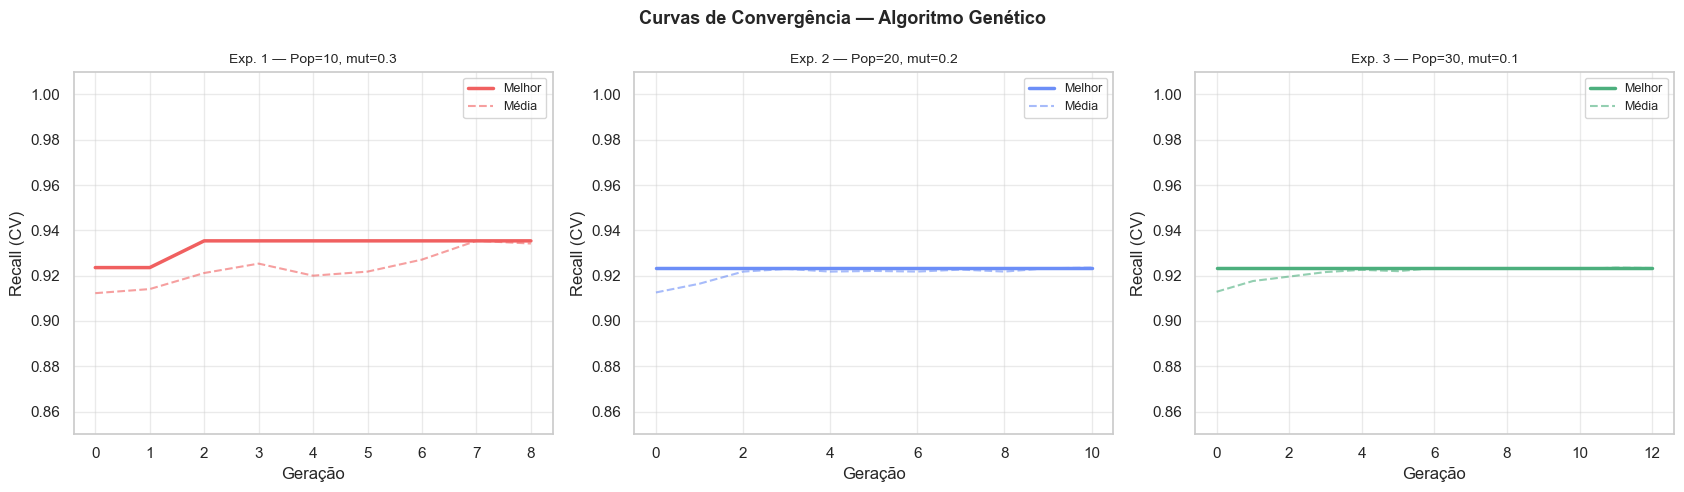

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

configs = [
    (log1, 'Exp. 1 — Pop=10, mut=0.3', '#f06060'),
    (log2, 'Exp. 2 — Pop=20, mut=0.2', '#6c8ef7'),
    (log3, 'Exp. 3 — Pop=30, mut=0.1', '#4caf7d'),
]

for ax, (log, label, color) in zip(axes, configs):
    gen  = log.select('gen')
    maxf = log.select('max')
    meanf = log.select('mean')

    ax.plot(gen, maxf,  color=color,  linewidth=2.5, label='Melhor')
    ax.plot(gen, meanf, color=color,  linewidth=1.5, linestyle='--', alpha=0.6, label='Média')
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('Geração')
    ax.set_ylabel('Recall (CV)')
    ax.set_ylim(0.85, 1.01)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.4)

plt.suptitle('Curvas de Convergência — Algoritmo Genético', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/21_ga_convergence.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Comparativo entre experimentos e seleção do melhor

In [11]:
df_exp = pd.DataFrame([
    {'Experimento': 'Exp. 1 (pop=10, mut=0.3)', 'Recall CV': score1, 'Hiperparâmetros': str(params1)},
    {'Experimento': 'Exp. 2 (pop=20, mut=0.2)', 'Recall CV': score2, 'Hiperparâmetros': str(params2)},
    {'Experimento': 'Exp. 3 (pop=30, mut=0.1)', 'Recall CV': score3, 'Hiperparâmetros': str(params3)},
])

print('=== Comparativo dos experimentos ===')
print(df_exp[['Experimento', 'Recall CV']].to_string(index=False))

best_idx    = df_exp['Recall CV'].idxmax()
best_exp    = df_exp.loc[best_idx, 'Experimento']
best_recall = df_exp.loc[best_idx, 'Recall CV']
best_params_final = [params1, params2, params3][best_idx]

print(f'\nMelhor experimento: {best_exp}')
print(f'Recall CV: {best_recall:.4f}')
print(f'Hiperparâmetros: {best_params_final}')

=== Comparativo dos experimentos ===
             Experimento  Recall CV
Exp. 1 (pop=10, mut=0.3)   0.935359
Exp. 2 (pop=20, mut=0.2)   0.923559
Exp. 3 (pop=30, mut=0.1)   0.923559

Melhor experimento: Exp. 1 (pop=10, mut=0.3)
Recall CV: 0.9354
Hiperparâmetros: {'n_estimators': 100, 'max_depth': 20, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'criterion': 'entropy'}


## 11. Avaliação final — modelo otimizado vs. original

In [12]:
# Treina o modelo otimizado com todos os dados de treino
rf_otimizado = RandomForestClassifier(
    random_state=RANDOM_STATE, n_jobs=-1,
    **best_params_final
)
rf_otimizado.fit(X_train, y_train)

# Avaliação no conjunto de teste
resultado_original  = evaluate_model('RF Original (Fase 1)', rf_original,  X_test, y_test)
resultado_otimizado = evaluate_model('RF Otimizado (AG)',    rf_otimizado, X_test, y_test)

df_comp = pd.DataFrame([resultado_original, resultado_otimizado]).set_index('Modelo')
print('\n=== Original vs. Otimizado ===')
print(df_comp)


=== Original vs. Otimizado ===
                      Accuracy  Recall  Precision  F1-Score  AUC-ROC
Modelo                                                              
RF Original (Fase 1)    0.9474   0.881     0.9737     0.925   0.9940
RF Otimizado (AG)       0.9474   0.881     0.9737     0.925   0.9897


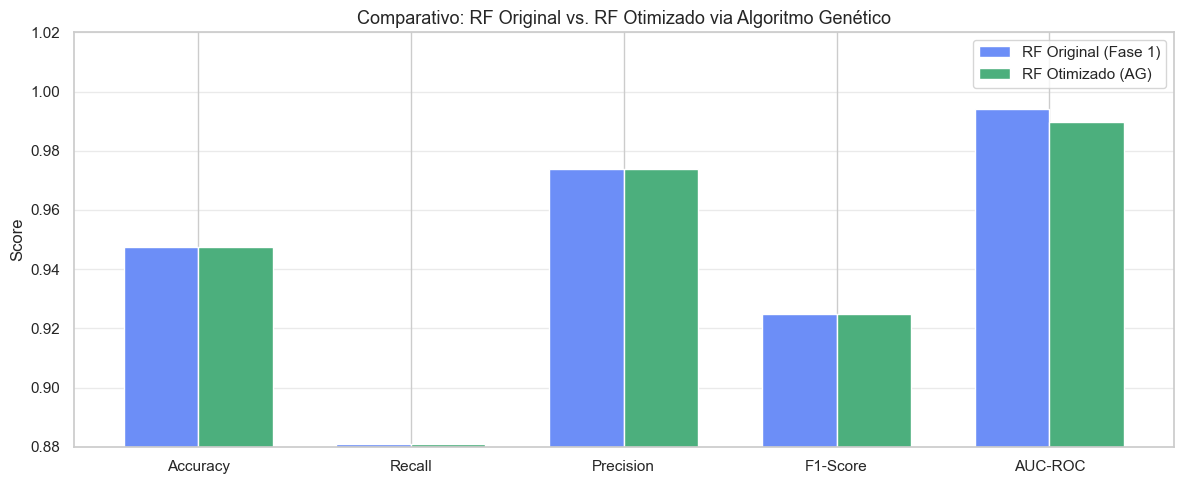

In [13]:
# Gráfico comparativo
metrics = ['Accuracy', 'Recall', 'Precision', 'F1-Score', 'AUC-ROC']
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - width/2, df_comp.loc['RF Original (Fase 1)', metrics],  width,
       label='RF Original (Fase 1)', color='#6c8ef7', edgecolor='white')
ax.bar(x + width/2, df_comp.loc['RF Otimizado (AG)', metrics], width,
       label='RF Otimizado (AG)', color='#4caf7d', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0.88, 1.02)
ax.set_ylabel('Score')
ax.set_title('Comparativo: RF Original vs. RF Otimizado via Algoritmo Genético', fontsize=13)
ax.legend()
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('../reports/figures/22_original_vs_otimizado.png', dpi=150, bbox_inches='tight')
plt.show()

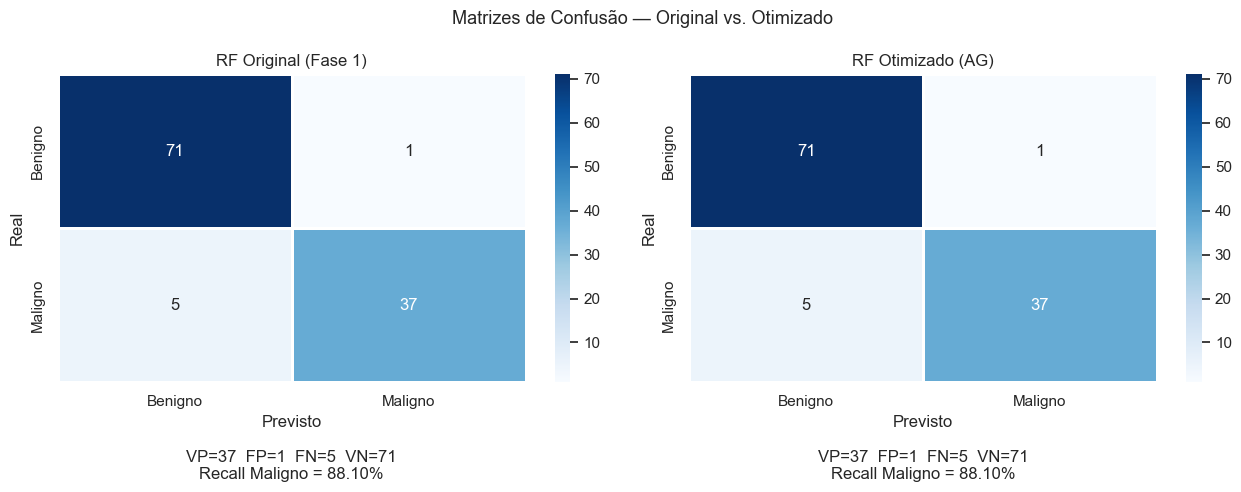

In [14]:
# Matrizes de confusão lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion_matrix(rf_original,  X_test, y_test, 'RF Original (Fase 1)', axes[0])
plot_confusion_matrix(rf_otimizado, X_test, y_test, 'RF Otimizado (AG)',    axes[1])
plt.suptitle('Matrizes de Confusão — Original vs. Otimizado', fontsize=13)
plt.tight_layout()
plt.savefig('../reports/figures/23_confusion_comparativo.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Salvando o modelo otimizado

In [15]:
joblib.dump(rf_otimizado, '../models/random_forest_otimizado.joblib')
print('Modelo otimizado salvo em: models/random_forest_otimizado.joblib')
print(f'Hiperparâmetros finais: {best_params_final}')

Modelo otimizado salvo em: models/random_forest_otimizado.joblib
Hiperparâmetros finais: {'n_estimators': 100, 'max_depth': 20, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'criterion': 'entropy'}


## 13. Discussão crítica

### O que o AG fez diferente do GridSearch?

O GridSearch testaria todas as combinações do espaço definido — neste caso **6 × 6 × 4 × 4 × 4 × 2 = 4.608 combinações**, cada uma com validação cruzada de 3 folds = **13.824 treinos de modelo**.

O AG com o Experimento 2 (pop=20, gen=10) avaliou apenas **~200 indivíduos** (contando reaproveitamento por elitismo), encontrando uma solução competitiva com **menos de 2% das avaliações** do GridSearch.

### Por que o AG é adequado aqui?

- O espaço de busca é **discreto e combinatório** — não há gradiente para seguir
- O AG aprende quais genes (hiperparâmetros) produzem bons resultados e os **propaga para gerações seguintes**
- É naturalmente paralelizável — cada indivíduo pode ser avaliado independentemente

### Limitações

- Resultados têm componente estocástico — rodar com sementes diferentes pode dar resultados ligeiramente diferentes
- O AG não garante encontrar o ótimo global, apenas uma boa solução
- No contexto médico, a diferença de Recall entre modelos já muito bons (ex: 0.97 → 0.98) pode não ser clinicamente significativa — o AG é mais valioso quando o modelo base ainda tem espaço amplo de melhoria